In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

from shared.common import load_config, plot_setup, save_figure

In [2]:
settings = load_config()
config = settings['field']
inp, out = Path('../input'), Path('../output')
C0 = config['log_scale_mg_m3']
rng = np.random.default_rng(settings['seed'])
palette = plot_setup()
labels = {
    'gaussian_briggs_raw': 'Briggs Gaussian, nominal', 'gaussian_briggs': 'Briggs Gaussian, fitted',
    'gaussian_met': 'Wind-variability Gaussian', 'ca_flat': 'CA, flat wind',
    'ca_shear': 'CA, shear', 'ca_dep': 'CA, deposition', 'ca_shear_dep': 'CA, shear + deposition',
    'ca_shear_high_dep': 'CA, shear + higher deposition',
}
supports = ['Arc receptors', 'Sampled arc peaks', 'Tower receptors']

In [3]:
pred = pd.read_csv(inp / 'predictions.csv')
runs = pd.read_csv(inp / 'runs.csv')
fits = pd.read_csv(inp / 'fit_parameters.csv')
flux = pd.read_csv(inp / 'field_mass_balance.csv')
grid = pd.read_csv(inp / 'refinement.csv')
benchmark = pd.read_csv(inp / 'benchmark_scores.csv')
coast = pd.read_csv(inp / 'scenario_summary.csv')
cols = ['run', 'met_day', 'array', 'radius_m', 'bearing_deg', 'z_m', 'observed_mg_m3']
long = pred.melt(id_vars=cols, value_vars=list(labels), var_name='model', value_name='pred_mg_m3')
arc = long.query("array == 'arc'")
tower = long.query("array == 'tower'")
peaks = arc.groupby(['model', 'met_day', 'run', 'radius_m'], as_index=False)[['observed_mg_m3', 'pred_mg_m3']].max()

In [4]:
evaluation = pd.concat([arc.assign(support=supports[0]), peaks.assign(support=supports[1]),
                        tower.assign(support=supports[2])], ignore_index=True)
evaluation['sq_log1p'] = (np.log1p(evaluation['pred_mg_m3']/C0)-np.log1p(evaluation['observed_mg_m3']/C0))**2
evaluation['abs_error_mg_m3'] = (evaluation['pred_mg_m3']-evaluation['observed_mg_m3']).abs()
ratio = evaluation['pred_mg_m3'].div(evaluation['observed_mg_m3'].replace(0, np.nan))
evaluation['fac2'] = ratio.between(0.5, 2).astype(float).where(ratio.notna())
metrics = ['sq_log1p', 'abs_error_mg_m3', 'observed_mg_m3', 'pred_mg_m3', 'fac2']
by_arc = evaluation.groupby(['support', 'model', 'met_day', 'run', 'radius_m'])[metrics].mean()
by_run = by_arc.groupby(level=['support', 'model', 'met_day', 'run']).mean()
by_day = by_run.groupby(level=['support', 'model', 'met_day']).mean()
field_metrics = by_day.groupby(level=['support', 'model']).mean().reset_index()
field_metrics['rmse_log1p'] = np.sqrt(field_metrics.pop('sq_log1p'))
field_metrics['frac_bias'] = 2*(field_metrics['pred_mg_m3']-field_metrics['observed_mg_m3']) / (
    field_metrics['pred_mg_m3']+field_metrics['observed_mg_m3'])
counts = evaluation.groupby(['support', 'model'], as_index=False).agg(
    days=('met_day', 'nunique'), runs=('run', 'nunique'), n=('observed_mg_m3', 'size'),
    n_positive=('fac2', 'count'))
field_metrics = field_metrics.merge(counts, on=['support', 'model'], validate='one_to_one')

In [5]:
# paired release-day resamples; OOF fits held fixed
comparisons = [
    ('Wind variability', 'gaussian_met', 'gaussian_briggs'),
    ('Matched Gaussian to lattice', 'ca_flat', 'gaussian_met'),
    ('Shear', 'ca_shear', 'ca_flat'),
    ('Deposition only', 'ca_dep', 'ca_flat'),
    ('Deposition with shear', 'ca_shear_dep', 'ca_shear'),
    ('Higher deposition with shear', 'ca_shear_high_dep', 'ca_shear_dep'),
    ('Shear + deposition vs matched Gaussian', 'ca_shear_dep', 'gaussian_met'),
    ('Shear + deposition vs fitted Briggs', 'ca_shear_dep', 'gaussian_briggs'),
]
intervals, paired = [], []
for support in supports:
    matrix = by_day.xs(support)['sq_log1p'].unstack('model')
    draws = rng.integers(0, len(matrix), size=(config['bootstrap_days'], len(matrix)))
    boot = np.sqrt(matrix.to_numpy()[draws].mean(axis=1))
    boot = pd.DataFrame(boot, columns=matrix.columns)
    centers = np.sqrt(matrix.mean())
    for model in labels:
        lo, hi = np.quantile(boot[model], [0.025, 0.975])
        intervals.append((support, model, lo, hi))
    for name, candidate, baseline in comparisons:
        lo, hi = np.quantile(boot[candidate]-boot[baseline], [0.025, 0.975])
        paired.append((support, name, candidate, baseline, centers[candidate]-centers[baseline], lo, hi))

intervals = pd.DataFrame(intervals, columns=['support', 'model', 'lo95', 'hi95'])
field_metrics = field_metrics.merge(intervals, on=['support', 'model'], validate='one_to_one')
paired = pd.DataFrame(paired, columns=['support', 'contrast', 'candidate', 'baseline', 'delta_rmse_log1p', 'lo95', 'hi95'])
per_radius = by_arc.groupby(level=['support', 'model', 'met_day', 'radius_m']).mean().groupby(
    level=['support', 'model', 'radius_m']).mean().reset_index()
per_radius['rmse_log1p'] = np.sqrt(per_radius.pop('sq_log1p'))

In [6]:
grid['squared_log_grid_diff'] = (np.log1p(grid['coarse_mg_m3']/C0)-np.log1p(grid['finer_mg_m3']/C0))**2
grid['abs_grid_diff_mg_m3'] = (grid['coarse_mg_m3']-grid['finer_mg_m3']).abs()
numeric = grid.groupby(['model', 'array', 'run'], as_index=False).agg(
    rms_log_diff=('squared_log_grid_diff', lambda a: np.sqrt(a.mean())),
    max_diff_mg_m3=('abs_grid_diff_mg_m3', 'max'))
matched = pred.assign(sq_log1p=(np.log1p(pred['ca_flat']/C0)-np.log1p(pred['gaussian_met']/C0))**2)
matched = matched.groupby('array', as_index=False).agg(
    rms_log_diff=('sq_log1p', lambda a: np.sqrt(a.mean())), receptors=('obs_id', 'size'))

In [7]:
field_metrics.to_csv(out / 'field_metrics.csv', index=False)
paired.to_csv(out / 'paired_day_bootstrap.csv', index=False)
per_radius.to_csv(out / 'field_metrics_by_radius.csv', index=False)
peaks.to_csv(out / 'sampled_arc_peaks.csv', index=False)
numeric.to_csv(out / 'grid_sensitivity.csv', index=False)
matched.to_csv(out / 'matched_gaussian_lattice_check.csv', index=False)
display(field_metrics[['support', 'model', 'runs', 'days', 'n', 'rmse_log1p', 'lo95', 'hi95',
                       'fac2', 'frac_bias']].sort_values(['support', 'rmse_log1p']).round(4))
display(paired.round(4))
display(matched.round(4))

,support,model,runs,days,n,rmse_log1p,lo95,hi95,fac2,frac_bias
5,Arc receptors,gaussian_briggs,44,20,4747,1.5890,1.2145,2.0036,0.2787,-0.3758
0,Arc receptors,ca_dep,44,20,4747,1.6410,1.2626,2.0712,0.2701,-0.5555
1,Arc receptors,ca_flat,44,20,4747,1.6465,1.2652,2.0802,0.2790,-0.4748
7,Arc receptors,gaussian_met,44,20,4747,1.6491,1.2659,2.0843,0.2785,-0.4801
3,Arc receptors,ca_shear_dep,44,20,4747,1.6502,1.2862,2.0589,0.2644,-0.4091
4,Arc receptors,ca_shear_high_dep,44,20,4747,1.6506,1.2875,2.0598,0.2634,-0.5104
2,Arc receptors,ca_shear,44,20,4747,1.6586,1.2880,2.0664,0.2806,-0.2434
6,Arc receptors,gaussian_briggs_raw,44,20,4747,2.0627,1.7485,2.3563,0.1485,-0.2721
14,Sampled arc peaks,gaussian_briggs_raw,44,20,220,1.0031,0.6018,1.4370,0.7065,0.1601
13,Sampled arc peaks,gaussian_briggs,44,20,220,1.2726,1.1083,1.4336,0.1645,-0.6929


,support,contrast,candidate,baseline,delta_rmse_log1p,lo95,hi95
0,Arc receptors,Wind variability,gaussian_met,gaussian_briggs,0.0601,0.0153,0.0956
1,Arc receptors,Matched Gaussian to lattice,ca_flat,gaussian_met,-0.0025,-0.0070,0.0014
2,Arc receptors,Shear,ca_shear,ca_flat,0.0121,-0.0250,0.0482
3,Arc receptors,Deposition only,ca_dep,ca_flat,-0.0056,-0.0114,0.0016
4,Arc receptors,Deposition with shear,ca_shear_dep,ca_shear,-0.0085,-0.0190,0.0027
5,Arc receptors,Higher deposition with shear,ca_shear_high_dep,ca_shear_dep,0.0004,-0.0033,0.0060
6,Arc receptors,Shear + deposition vs matched Gaussian,ca_shear_dep,gaussian_met,0.0011,-0.0334,0.0321
7,Arc receptors,Shear + deposition vs fitted Briggs,ca_shear_dep,gaussian_briggs,0.0612,0.0052,0.1171
8,Sampled arc peaks,Wind variability,gaussian_met,gaussian_briggs,0.0512,-0.0234,0.1381
9,Sampled arc peaks,Matched Gaussian to lattice,ca_flat,gaussian_met,-0.0061,-0.0122,-0.0004


,array,rms_log_diff,receptors
0,arc,0.0309,4747
1,tower,0.0124,1990


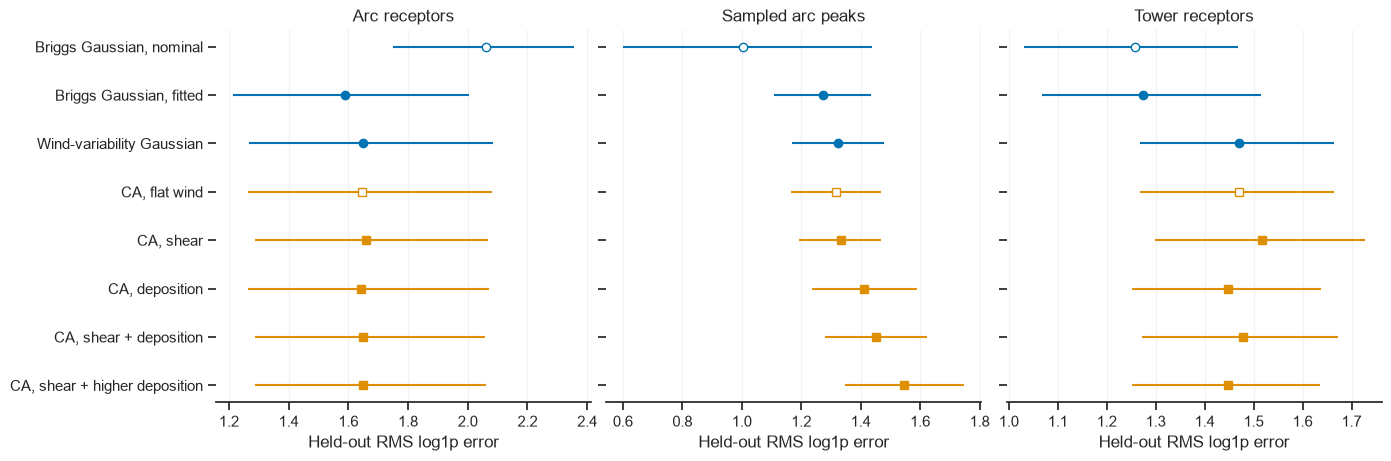

In [8]:
fig, axs = plt.subplots(1, 3, figsize=(13.8, 4.5), sharey=True, layout='constrained')
for ax, support in zip(axs, supports):
    m = field_metrics.set_index(['support', 'model']).loc[support]
    for i, key in enumerate(labels):
        s = m.loc[key]
        color = palette[0 if key.startswith('gaussian') else 1]
        marker = 'o' if key.startswith('gaussian') else 's'
        ax.hlines(i, s.lo95, s.hi95, color=color, lw=1.5)
        ax.plot(s.rmse_log1p, i, marker, color=color, ms=6, mfc='white' if i in (0, 3) else color)
    ax.set_title(support)
    ax.set_xlabel('Held-out RMS log1p error')
    ax.grid(axis='x', alpha=0.22)
axs[0].set_yticks(range(len(labels)), list(labels.values()))
axs[0].invert_yaxis()
sns.despine(fig=fig, left=True)
save_figure(fig, out, 'field_skill')
display(fig)
plt.close(fig)

/Users/slmagid/Desktop/MOCS/pdp_gaussian_plume_ca/f_evaluate/src/shared/common.py:44: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.savefig(output / f'{name}.png', dpi=160, bbox_inches='tight', facecolor='white')
/Users/slmagid/Desktop/MOCS/pdp_gaussian_plume_ca/f_evaluate/src/shared/common.py:45: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.savefig(output / f'{name}.pdf', bbox_inches='tight', facecolor='white')
/Users/slmagid/miniforge3/envs/research313/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


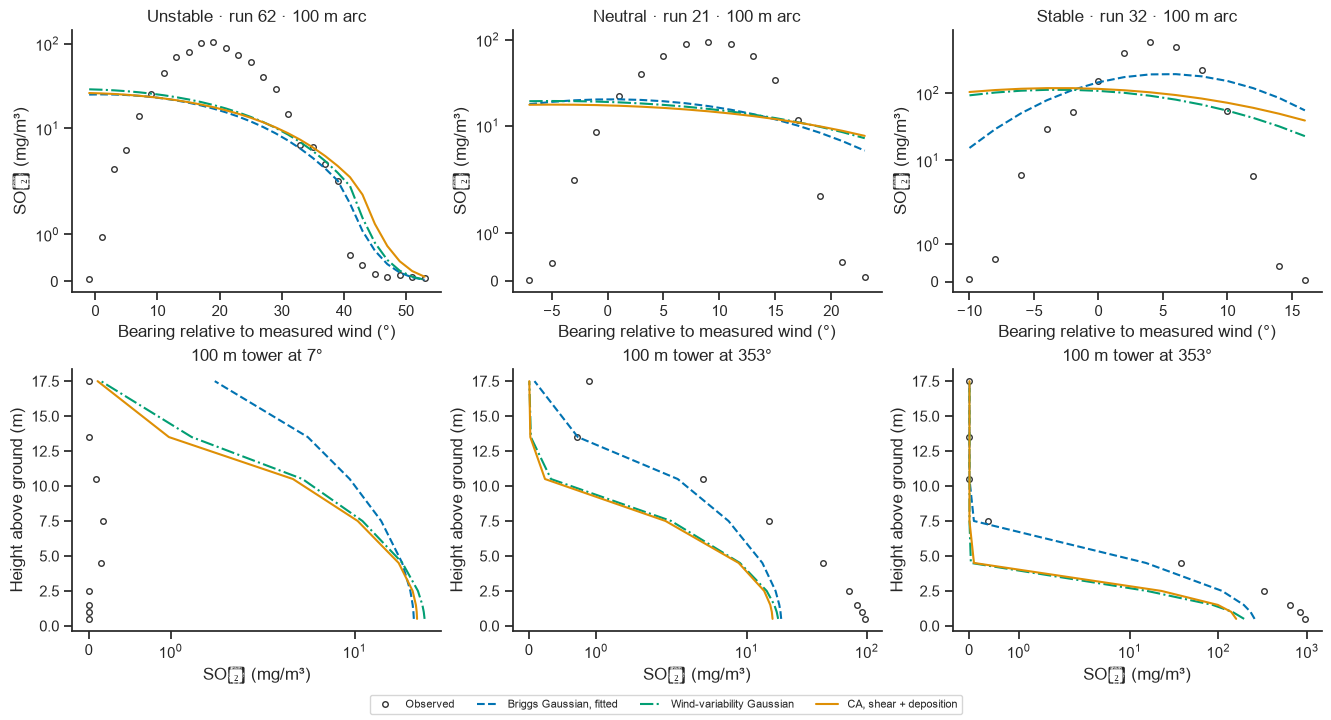

In [9]:
# illustrative held-out runs selected on met alone, among tower-available releases
tower_runs = runs.loc[runs['run'].isin(tower['run'])].copy()
tower_runs['class_group'] = pd.cut(tower_runs['stability'], bins=[0, 3, 4, 6],
                                    labels=['Unstable', 'Neutral', 'Stable'])
examples = (tower_runs.sort_values(['u2_m_s', 'run']).groupby('class_group', observed=True)['run']
            .agg(lambda group: group.iloc[len(group)//2]))
styles = [('gaussian_briggs', '--', palette[0]), ('gaussian_met', '-.', palette[2]),
          ('ca_shear_dep', '-', palette[1])]
fig, axes = plt.subplots(2, len(examples), figsize=(13.2, 7.1), layout='constrained')
for j, (regime, run) in enumerate(examples.items()):
    toward = runs.loc[runs['run'].eq(run), 'toward_deg'].iat[0]
    arc_example = pred.query("run == @run and array == 'arc' and radius_m == 100").copy()
    arc_example['azimuth'] = (arc_example['bearing_deg']-toward + 180) % 360-180
    arc_example = arc_example.sort_values('azimuth')
    tower_example = pred.query("run == @run and array == 'tower'").copy()
    tower_example['angular_dist'] = np.abs((tower_example['bearing_deg']-toward + 180) % 360-180)
    bearing = tower_example.sort_values(['angular_dist', 'bearing_deg'])['bearing_deg'].iat[0]
    tower_example = tower_example.query('bearing_deg == @bearing').sort_values('z_m')
    axes[0, j].plot(arc_example['azimuth'], arc_example['observed_mg_m3'],
                    'o', mfc='white', mec='0.2', ms=4, label='Observed')
    axes[1, j].plot(tower_example['observed_mg_m3'], tower_example['z_m'],
                    'o', mfc='white', mec='0.2', ms=4, label='Observed')
    for key, line, color in styles:
        axes[0, j].plot(arc_example['azimuth'], arc_example[key], line, color=color, label=labels[key])
        axes[1, j].plot(tower_example[key], tower_example['z_m'], line, color=color, label=labels[key])
    axes[0, j].set(title=f'{regime} · run {run} · 100 m arc', yscale='symlog',
                   xlabel='Bearing relative to measured wind (°)', ylabel='SO₂ (mg/m³)')
    axes[1, j].set(title=f'100 m tower at {bearing:g}°', xscale='symlog',
                   xlabel='SO₂ (mg/m³)', ylabel='Height above ground (m)')
handles, legend_labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc='outside lower center', ncol=4, fontsize=8)
sns.despine(fig=fig)
save_figure(fig, out, 'field_profiles')
display(fig)
plt.close(fig)

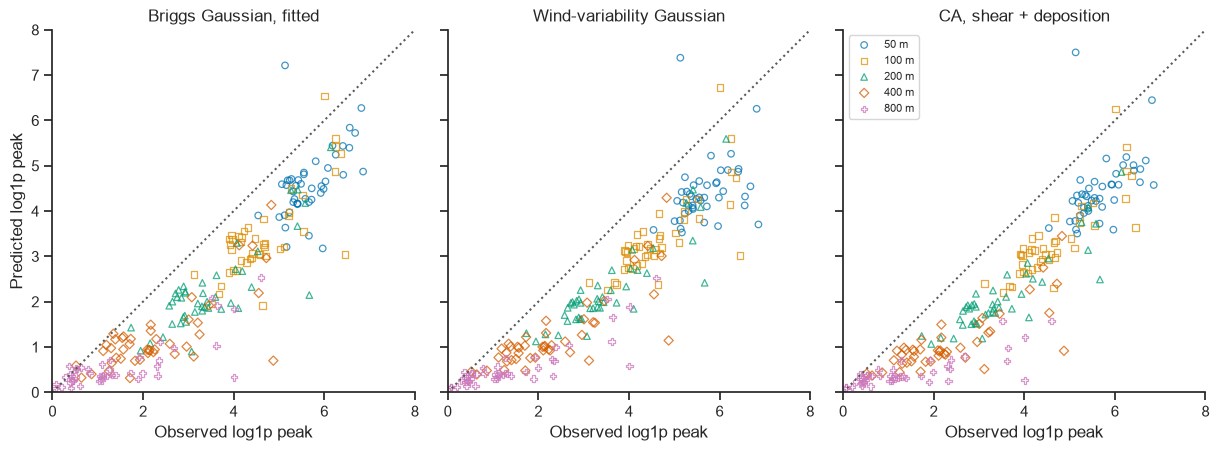

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(12.2, 4.4), layout='constrained', sharex=True, sharey=True)
marker = {50: 'o', 100: 's', 200: '^', 400: 'D', 800: 'P'}
for ax, (key, _, _) in zip(axes, styles):
    data = peaks.query('model == @key')
    for i, (radius, rows) in enumerate(data.groupby('radius_m')):
        ax.scatter(np.log1p(rows['observed_mg_m3']/C0), np.log1p(rows['pred_mg_m3']/C0),
                   marker=marker[radius], facecolors='none', edgecolors=palette[i], s=22, lw=0.9,
                   alpha=0.75, label=f'{radius:g} m')
    ax.plot([0, 8], [0, 8], ':', color='0.35')
    ax.set(aspect='equal', xlim=(0, 8), ylim=(0, 8), title=labels[key], xlabel='Observed log1p peak')
axes[0].set_ylabel('Predicted log1p peak')
axes[-1].legend(fontsize=8)
sns.despine(fig=fig)
save_figure(fig, out, 'field_arc_peaks')
display(fig)
plt.close(fig)

In [11]:
bench_rows = benchmark.query("test == 'pulse_cell_mass' and time_s == 20").sort_values('spacing_m', ascending=False)
slice_rows = benchmark.query("test == 'finite_release_profile'").sort_values('spacing_m', ascending=False)
bench_line = ', '.join(f'{r.rel_l1:.2%} at {r.spacing_m:g} m' for r in bench_rows.itertuples())
slice_line = ', '.join(f'{r.rel_l1:.2%} at {r.spacing_m:g} m' for r in slice_rows.itertuples())
full = coast.set_index('scenario').loc['Full']
by_support = field_metrics.pivot(index='model', columns='support', values='rmse_log1p').reindex(labels)
metrics_md = [
    '| Model | Arc receptors | Sampled arc peaks | Tower receptors |',
    '| --- | ---: | ---: | ---: |',
]
for key, vals in by_support[supports].iterrows():
    metrics_md.append(f"| {labels[key]} | " + " | ".join(f'{v:.3f}' for v in vals) + ' |')
focus = paired.loc[paired['contrast'].eq('Shear + deposition vs matched Gaussian')].set_index('support')
differences = []
for support in supports:
    r = focus.loc[support]
    differences.append(f'- {support} **{r.delta_rmse_log1p:+.3f}** [{r.lo95:+.3f}, {r.hi95:+.3f}]')
arc_counts = field_metrics.query("support == 'Arc receptors'").iloc[0]
tower_counts = field_metrics.query("support == 'Tower receptors'").iloc[0]
match_largest = matched['rms_log_diff'].max()
grid_largest = numeric['rms_log_diff'].max()
max_flux_error = flux['balance_residual_frac'].abs().max()
mean_sink = flux.query("model == 'ca_shear_dep'")['deposited_frac'].mean()
deposition_only = paired.loc[paired['contrast'].eq('Deposition only')].set_index('support')
tower_dep = deposition_only.loc['Tower receptors', 'delta_rmse_log1p']
peak_dep = deposition_only.loc['Sampled arc peaks', 'delta_rmse_log1p']
lines = [
    '# Run results', '', '## Analytic benchmark', '',
    f'- Pulse relative L1 cell-mass error at 20 s was {bench_line}.',
    f'- Finite-release crosswind profile relative L1 error was {slice_line}.',
    '', '## Coastal carbon toy model', '',
    f"- The full run released {full['emitted_total_kg_c']:,.1f} kg C and converted {full['reacted_kg_c']:.1f} kg C from VOC to aerosol.",
    f"- At the end, {full['land_kg_c']:.1f} kg C was in the land pool and {full['ocean_kg_c']:.1f} kg C in the ocean pool.",
    f"- Maximum absolute mass-balance residual across scenarios was {coast['max_balance_abs_kg_c'].max():.2g} kg C.",
    '', '## Prairie Grass', '',
    f"Out-of-fold predictions cover {arc_counts.runs} runs on {arc_counts.days} meteorological dates, with "
    f"{arc_counts.n:,} arc measurements and {tower_counts.n:,} tower measurements from {tower_counts.runs} runs. "
    'Values below are day-weighted RMS errors of log(1 + C / C₀), with C₀ = 1 mg/m³ by default.',
    '', *metrics_md, '',
    'Paired changes for the shear-plus-deposition lattice versus its matched wind-variability Gaussian. '
    'Negative values favor the lattice. Intervals resample meteorological dates with fitted models fixed.',
    '', *differences, '',
    f'Deposition alone changed tower error by {tower_dep:+.3f} and sampled arc-peak error by {peak_dep:+.3f} '
    'relative to the flat-wind lattice.',
    '',
    f'- The matched flat-wind lattice and Gaussian differed by at most {match_largest:.3f} RMS log1p across the two receptor arrays.',
    f'- Doubling resolution changed predictions by at most {grid_largest:.3f} RMS log1p in any audited run × array × model.',
    f'- Maximum relative flux ledger residual was {max_flux_error:.2g}. The shear-plus-deposition run deposited '
    f'{mean_sink:.1%} of emitted mass on average by the last downwind receptor plane.',
    f"- Width or bearing calibration reached a configured bound in {int(fits['at_bound'].sum())} of {len(fits)} fits.",
    '', '[Held-out scores](field_skill.pdf) · [Receptor profiles](field_profiles.pdf) · [Sampled arc peaks](field_arc_peaks.pdf)',
    '', 'See the CSVs for model contrasts, scores by radius, run-level flux accounting, and numerical refinement.',
]
(out / 'RESULTS.md').write_text('\n'.join(lines) + '\n')

2372